# HelpMate Assignment

## Upgrad Cohort
- ACP GenAI C01

## Student
- SAI MITRA JANDHYALA
- email: mitra.jandhyala@gmail.com

## Project Details:
### Project Name: GenAI Retrieval Augmented Search
### Goal: Generative Search based HelpMate to look for Movies based on user's description.
### Project Type: Option 1: Build Your Own Project (BYOP)


### Setup:
- Kaggle dataset https://www.kaggle.com/datasets/jrobischon/wikipedia-movie-plots has to extracted and the archive csv should be renamed as 'wiki_movie_plots_deduped.csv' in the same folder where this notebook executes.
- Open AI Key needs to be available in the OpenAI_API_Key.txt files in the same folder where this notebook executes.

# Overall System Design
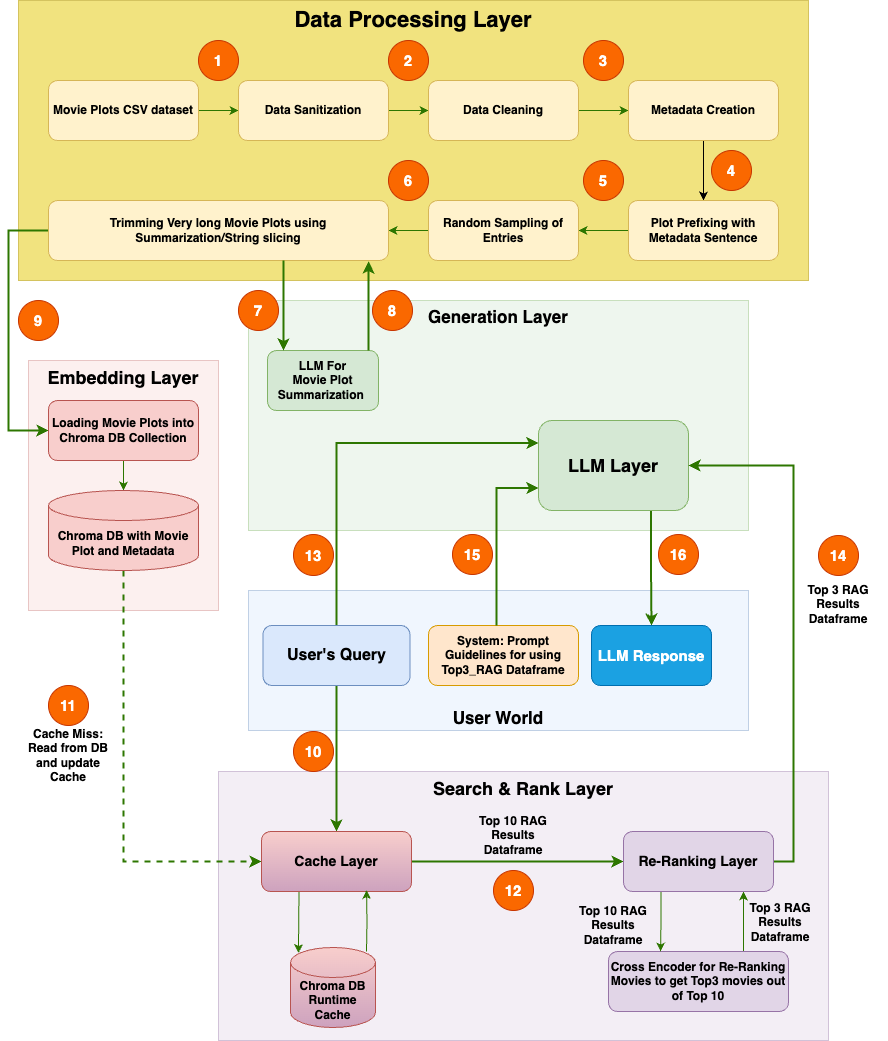

# Overall System Design explained

## As shown above the System includes various layer. Primarily all layers are represented in pale colored boxes representing the type of work they undertake.

### Data Processing Layer: Steps 1 to 9 are initial data processing steps leading upto Chroma DB persistance of Movies and their Movie plots

### Embedding Layer: Chroma DB persistance of Movie Plots along with their Metadata like Title, Release year etc into vector DB for semantic search

### - Search and Rank Layer: Has Caching and Cross-Encoder re-ranking results and providing top 3 movies to the Generation layer.

### - Generation Layer: LLM Takes User's Query, Top 3 Movies dataframe and System prompt as inputs and produces a user freindly LLM Response

### - User World: Consister of User's query, System prompt and LLM Response which exist as user facing messages or user interacting messages or system messages designed by the HelpMate developer


## Project libraries needed

In [128]:
!pip install openai
!pip install chromaDB
!pip install sentence-transformers

## Project imports

In [129]:
import requests
from pathlib import Path
import pandas as pd
from operator import itemgetter
import json
import openai
import chromadb

# OpenAI embedding function to convert movie plot texts into vectors
from chromadb.utils.embedding_functions import OpenAIEmbeddingFunction

# once some movies are selected, re-ranking them based on Cross Encoder
from sentence_transformers import CrossEncoder, util

from google.colab import drive

import textwrap

### For Google Drive access to dataset and OpenAI API key file, set Is_Google_Drive to True and provide the correct drive_path.

If Is_Google_Drive is False, the code assumes that OpenAI API key file and dataset are in the same folder where this notebook runs.

In [130]:
Is_Google_Drive = True

if Is_Google_Drive:
  # Mount Google Drive
  drive.mount('/content/drive', force_remount=True)
  drive_path = '/content/drive/My Drive/<provide your google drive path here>'
else:
  # point to current folder
  drive_path = './'

Mounted at /content/drive


### Load the Open API key in OpenAI_API_Key.txt

In [131]:
# Set the API key
with open(drive_path + "OpenAI_API_Key.txt", "r") as f:
  openai.api_key = ' '.join(f.readlines())

### Dataloading: Load the movie plots summary dataset file

In [132]:
# movie plots csv file
movie_plots_csv_path = drive_path + 'wiki_movie_plots_deduped.csv'

### Data inspection: Inspect the dataset

In [133]:
# prepare dataframe of movie plots
movie_plots_df = pd.read_csv(movie_plots_csv_path)
movie_plots_df.tail(5)

,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot
34881,2014,The Water Diviner,Turkish,Director: Russell Crowe,Director: Russell Crowe\r\nCast: Russell Crowe...,unknown,https://en.wikipedia.org/wiki/The_Water_Diviner,"The film begins in 1919, just after World War ..."
34882,2017,Çalgı Çengi İkimiz,Turkish,Selçuk Aydemir,"Ahmet Kural, Murat Cemcir",comedy,https://en.wikipedia.org/wiki/%C3%87alg%C4%B1_...,"Two musicians, Salih and Gürkan, described the..."
34883,2017,Olanlar Oldu,Turkish,Hakan Algül,"Ata Demirer, Tuvana Türkay, Ülkü Duru",comedy,https://en.wikipedia.org/wiki/Olanlar_Oldu,"Zafer, a sailor living with his mother Döndü i..."
34884,2017,Non-Transferable,Turkish,Brendan Bradley,"YouTubers Shanna Malcolm, Shira Lazar, Sara Fl...",romantic comedy,https://en.wikipedia.org/wiki/Non-Transferable...,The film centres around a young woman named Am...
34885,2017,İstanbul Kırmızısı,Turkish,Ferzan Özpetek,"Halit Ergenç, Tuba Büyüküstün, Mehmet Günsür, ...",romantic,https://en.wikipedia.org/wiki/%C4%B0stanbul_K%...,The writer Orhan Şahin returns to İstanbul aft...


### Lets examine the entries in the dataset

In [134]:
movie_plots_df.shape

(34886, 8)

Conclusion: Lot of entries present. We have liberty to filter out entries based on some condition like too short movie plot descriptions etc

# Processing the text data:
## Data Sanitization: Fill NA values with "unknown"

In [135]:
movie_plots_df.fillna('unknown', inplace=True)

## Reset index for iteration through the dataset

In [136]:
movie_plots_df.reset_index(inplace=True)

## Compute the word length of each movie plot to check if the summaries are long enough to consider for vectorization.

In [137]:
movie_plots_df['Plot_Text_Len'] = 0

for index in movie_plots_df.index:
    movie_plots_df.loc[index, 'Plot_Text_Len'] =  len(str(movie_plots_df.loc[index,'Plot']).split(' '))

In [138]:
movie_plots_df['Plot_Text_Len'].describe()

count    34886.000000
mean       369.688242
std        313.240182
min          2.000000
25%        121.250000
50%        282.000000
75%        576.000000
max       6731.000000
Name: Plot_Text_Len, dtype: float64

### Conclusion: Maximum size of movie plot is 6731 characters which seems to be an outlier.

## Lets define the min and max of plot word lengths.
- We will remove entries with  < min plot word length.
- We will strip plots of entries with > max plot word length.

In [139]:
MIN_PLOT_LENGTH = 5
MAX_PLOT_LENGTH = 1000

### Lets check how many entries exist in the dataset big plot sizes

In [140]:
movie_plots_df[movie_plots_df['Plot_Text_Len'] > MAX_PLOT_LENGTH]

,index,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot,Plot_Text_Len
551,551,1925,Phantom of the Opera,American,Rupert Julian,"Lon Chaney, Mary Philbin, Norman Kerry",horror,https://en.wikipedia.org/wiki/The_Phantom_of_t...,The film opens with the debut of the new seaso...,1420
650,650,1927,My Best Girl,American,Sam Taylor,"Mary Pickford, Buddy Rogers",romantic comedy,https://en.wikipedia.org/wiki/My_Best_Girl_(19...,The film starts out at The Merrill Department ...,1264
867,867,1929,The Valiant,American,William K. Howard,"Paul Muni, Marguerite Churchill",drama,https://en.wikipedia.org/wiki/The_Valiant_(192...,The credits (accompanied by organ music endemi...,1410
872,872,1929,Welcome Danger,American,"Clyde Bruckman, Malcolm St. Clair",Harold Lloyd,comedy,https://en.wikipedia.org/wiki/Welcome_Danger,"Harold Bledsoe, a student of botany, is travel...",1050
899,899,1930,Call of the Flesh,American,Charles Brabin,"Ramón Novarro, Dorothy Jordan, Ernest Torrence",musical,https://en.wikipedia.org/wiki/Call_of_the_Flesh,"In Seville, Spain, a cantina is located across...",1043
...,...,...,...,...,...,...,...,...,...,...
34709,34709,2015,Dino Time,South_Korean,"Choi Yoon-suk, John Kafka","Pamela Adlon, Tara Strong",unknown,https://en.wikipedia.org/wiki/Dino_Time,Ernie Fitzpatrick (Pamela Adlon) is a daredevi...,1064
34769,34769,2016,Missing,South_Korean,Lee Eon-hee,"Uhm Ji-won, Gong Hyo-jin",unknown,https://en.wikipedia.org/wiki/Missing_(2016_film),Ji-sun is a workaholic divorced woman working ...,3286
34791,34791,2017,The Villainess,South_Korean,Jung Byung-gil,"Kim Ok-bin, Shin Ha-kyun, Sung Joon",unknown,https://en.wikipedia.org/wiki/The_Villainess,In the opening scene of the movie an unnamed h...,1201
34800,34800,2017,Memoir of a Murderer,South_Korean,Won Shin-yun,"Sol Kyung-gu, Kim Nam-gil, Seolhyun, Oh Dal-su",unknown,https://en.wikipedia.org/wiki/Memoir_of_a_Murd...,Byeong-soo (Sol Kyung-gu) was a serial killer....,1128


### Conclusion: There are about 1000 entries with more than MAX_PLOT_LENGTH words in the plot. We can trim plot texts for these entries. Lets go for trimming these large values after selecting a sub-set of dataset instead on applying trimming on the entire dataset of about 30000+ entries. We are working with a subset of movies data (due to limitations with OpenAI RPM) and hence it would not be optimal to trim entries with big movie plot well in advance. Lets push this activity post random sample selection.

## Lets see how many entries exist with very less words desribing the movie plot.

In [141]:
movie_plots_df[movie_plots_df['Plot_Text_Len'] < MIN_PLOT_LENGTH]

,index,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot,Plot_Text_Len
7429,7429,1960,Walk Like a Dragon,American,James Clavell,"Jack Lord, Nobu McCarthy, Mel Torme",drama,https://en.wikipedia.org/wiki/Walk_Like_a_Dragon,Film's introduction:,2
7606,7606,1962,Heaven and Earth Magic,American,Harry Everett Smith,unknown,animated,https://en.wikipedia.org/wiki/Heaven_and_Earth...,Smith explains:,2
27018,27018,2014,Desi Kattey,Bollywood,Anand Kumar,"Suniel Shetty, Akhil Kapur, Jay Bhanushali, Sa...",drama/action,https://en.wikipedia.org/wiki/Desi_Kattey,{{no plott}||date=January 2018}},3
29020,29020,1951,Sudharshan,Tamil,Sundar Rao Nadkarni / A. S. A. Sami,"P. U. Chinnappa, P. Kannamba, (Yogam) Mangalam...",unknown,https://en.wikipedia.org/wiki/Sudharshan,Refer this for details.,4
33373,33373,2002,A Saloon Wet with Beautiful Women,Japanese,Tatsurō Kashihara,Koharu Yamasaki,pink,https://en.wikipedia.org/wiki/A_Saloon_Wet_wit...,An erotic romance.[4],3


### Conlusion: Only about a few entries which have less than MIN_PLOT_LENGTH words in Plot description.

## Lets remove entries with less words desribing the movie plot. These movie plots don't offer any significant information and we will remove them right away.

In [142]:
movie_plots_df = movie_plots_df[movie_plots_df['Plot_Text_Len'] >= MIN_PLOT_LENGTH]

## Utility function to produce a metadata dictionary helpful while vectorizing movie plots using ChromaDB Client

In [143]:
def set_movie_metadata(x):
  meta_dict = \
  {
      'Release Year': x['Release Year'],
      'Title': x['Title'],
      'Origin/Ethnicity': x['Origin/Ethnicity'],
      'Director': x['Director'],
      'Cast': x['Cast'],
      'Genre': x['Genre'],
  }
  return meta_dict

## Creating a 'Metadata' column in the dataset for every movie entry

In [144]:
movie_plots_df['Metadata'] = movie_plots_df.apply(set_movie_metadata, axis=1)

## A function to append metadata column at the end of the plot

In [145]:
def append_metadata_to_plot(movie_plots_df):
  movie_plots_df_len = len(movie_plots_df)
  for index in movie_plots_df.index:
    movie_plots_df.loc[index, 'Plot'] =  str(movie_plots_df.loc[index,'Plot'])+ ". Metadata:" + str(movie_plots_df.loc[index,'Metadata'])

## A function to convert metadata dictionary into a sentence and prefix this at the beginning to every movie plot.
- This method is useful because it adds the Title, Release Year, Cast, Genre, Origin/Ethnicity into the plot itself.
- This approach will help figure out user's queries in a better way as most of the challenges required to be filled out in results by the LLM Chat tool will be part of the plot itself instead of looking into the Metadata column of the vector DB

In [146]:
def get_metadata_as_sentence(metadata):
  metadata_sentence = f"The title of the movie is '{metadata['Title']}' released in the year {metadata['Release Year']}. "
  if metadata['Cast'].lower() != 'unknown':
    metadata_sentence = metadata_sentence + f"Cast includes {metadata['Cast']}. "
  if metadata['Genre'].lower() != 'unknown':
    metadata_sentence = metadata_sentence + f"It is of Genre {metadata['Genre']}. "
  if metadata['Origin/Ethnicity'].lower() != 'unknown':
    metadata_sentence = metadata_sentence + f"It is of Origin/Ethnicity {metadata['Origin/Ethnicity']}."
  return metadata_sentence

def add_metadata_sentence_prefix_to_plot(movie_plots_df):
  movie_plots_df_len = len(movie_plots_df)
  for index in movie_plots_df.index:
    movie_plots_df.loc[index, 'Plot'] =  get_metadata_as_sentence(movie_plots_df.loc[index,'Metadata']) +' #### Plot: '+ str(movie_plots_df.loc[index,'Plot'])

## Out of 2 methods 'append_metadata_to_plot' and 'add_metadata_sentence_prefix_to_plot', we will be choosing the latter one i.e., 'add_metadata_sentence_prefix_to_plot' as it enhances our searching power.

### Lets invoke 'add_metadata_sentence_prefix_to_plot' method on the dataset to prefix the plots with metadata information.

In [147]:
add_metadata_sentence_prefix_to_plot(movie_plots_df)

## A look at the dataset after altering the plots with metadata prefixes.

In [148]:
movie_plots_df.head()

,index,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot,Plot_Text_Len,Metadata
0,0,1901,Kansas Saloon Smashers,American,Unknown,unknown,unknown,https://en.wikipedia.org/wiki/Kansas_Saloon_Sm...,The title of the movie is 'Kansas Saloon Smash...,83,"{'Release Year': 1901, 'Title': 'Kansas Saloon..."
1,1,1901,Love by the Light of the Moon,American,Unknown,unknown,unknown,https://en.wikipedia.org/wiki/Love_by_the_Ligh...,The title of the movie is 'Love by the Light o...,86,"{'Release Year': 1901, 'Title': 'Love by the L..."
2,2,1901,The Martyred Presidents,American,Unknown,unknown,unknown,https://en.wikipedia.org/wiki/The_Martyred_Pre...,The title of the movie is 'The Martyred Presid...,75,"{'Release Year': 1901, 'Title': 'The Martyred ..."
3,3,1901,"Terrible Teddy, the Grizzly King",American,Unknown,unknown,unknown,"https://en.wikipedia.org/wiki/Terrible_Teddy,_...","The title of the movie is 'Terrible Teddy, the...",153,"{'Release Year': 1901, 'Title': 'Terrible Tedd..."
4,4,1902,Jack and the Beanstalk,American,"George S. Fleming, Edwin S. Porter",unknown,unknown,https://en.wikipedia.org/wiki/Jack_and_the_Bea...,The title of the movie is 'Jack and the Beanst...,140,"{'Release Year': 1902, 'Title': 'Jack and the ..."


## Due to Open AI RPM limitations, lets randomly select only a few movie entries as our search source.

In [149]:
RANDOM_SAMPLE_SIZE = 1600
movie_plots_df_mini = movie_plots_df.sample(n = RANDOM_SAMPLE_SIZE)
movie_plots_df_mini.reset_index(inplace=True)

## Lets trim the Plot value of subset of movie entries selected using text summarization feature of OpenAI API itself

In [150]:
long_plots_df = movie_plots_df_mini[movie_plots_df_mini['Plot_Text_Len'] > MAX_PLOT_LENGTH]
long_plots_df.head()

,level_0,index,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot,Plot_Text_Len,Metadata
2,7881,7881,1964,The Masque of the Red Death,American,Roger Corman,"Vincent Price, Hazel Court",horror,https://en.wikipedia.org/wiki/The_Masque_of_th...,The title of the movie is 'The Masque of the R...,1170,"{'Release Year': 1964, 'Title': 'The Masque of..."
33,23313,23313,1991,Riki-Oh: The Story of Ricky,Hong Kong,Lam Nai-choi,"Fan Siu-wong, Fan Mei Sheng, Ka-Kui Ho",martial arts / action / comedy / prison,https://en.wikipedia.org/wiki/Riki-Oh:_The_Sto...,The title of the movie is 'Riki-Oh: The Story ...,1052,"{'Release Year': 1991, 'Title': 'Riki-Oh: The ..."
54,29810,29810,1989,En Rathathin Rathame,Tamil,K. Vijayan Sundar K. Vijayan,"K. Bhagyaraj, Meenakshi Seshadri, Janagaraj",unknown,https://en.wikipedia.org/wiki/En_Rathathin_Rat...,The title of the movie is 'En Rathathin Ratham...,1208,"{'Release Year': 1989, 'Title': 'En Rathathin ..."
80,21064,21064,2010,Centurion,British,Neil Marshall,"Michael Fassbender, Dominic West, Olga Kurylen...",drama,https://en.wikipedia.org/wiki/Centurion_(film),The title of the movie is 'Centurion' released...,1083,"{'Release Year': 2010, 'Title': 'Centurion', '..."
197,21200,21200,2011,War Horse,British,Director: Steven Spielberg,Director: Steven Spielberg\r\nCast: Emily Wats...,unknown,https://en.wikipedia.org/wiki/War_Horse_(film),The title of the movie is 'War Horse' released...,1167,"{'Release Year': 2011, 'Title': 'War Horse', '..."


In [151]:
long_plots_df.shape

(37, 12)

### Conclusion: Out of random samples, a few might be having plot word length > MAX_PLOT_LENGTH, lets use text summarization method 'generate_movie_plot_summary' to generate concise summary for these entries

### A utility function to generate movie plot summary for movies with a cap of MAX_PLOT_LENGTH words

In [152]:
def generate_movie_plot_summary(movie_plot):
  summarization_instruction = [{"role": "user", "content":f"Please summarize the following text:\n {movie_plot}\n"}]
  response = openai.ChatCompletion.create(
        model="gpt-3.5-turbo-16k",
        messages=summarization_instruction,
        max_tokens = MAX_PLOT_LENGTH
    )
  summary_text = response['choices'][0]['message']['content'].split('\n')
  # if we happen to get summary like a list, we pick the first item from it
  if (type(summary_text)) == list and len(summary_text) > 0:
    summary_text = summary_text[0]
  else:
    summary_text = str(summary_text)

  if (summary_text[0]) == '[' and (summary_text[-1]) == ']':
    summary_text = summary_text[1:-1]

  if (summary_text[0]) == '\'' and (summary_text[-1]) == '\'':
    summary_text = summary_text[1:-1]

  if (summary_text[0]) == '"' and (summary_text[-1]) == '"':
    summary_text = summary_text[1:-1]

  return summary_text

### A utility function to strip movie plot summary to a cap of MAX_PLOT_LENGTH words.
- This is not effective but plot summarization is costly and OpenAI does not seem to entertain continuous requests for summarization.
- Also, most of the plot is captured in the first 1000 words so stripping upto this length will not affect the search capabilities

In [153]:
def strip_long_plots(movie_plot, max_size=MAX_PLOT_LENGTH):
  movie_plot_word_list = movie_plot.split(' ')
  if len(movie_plot_word_list) > max_size:
    return ' '.join(movie_plot_word_list[0:max_size])
  return movie_plot

## Chunking strategy: Text summarization has limitations on RPM on Open AI hence choosing 'strip_long_plots' function over the function 'generate_movie_plot_summary' to strip longer plots to 1000 words (MAX_PLOT_LENGTH)

In [154]:
for index in movie_plots_df_mini.index:
  if movie_plots_df_mini.loc[index, 'Plot_Text_Len'] > MAX_PLOT_LENGTH:
    movie_plots_df_mini.loc[index, 'Plot'] = strip_long_plots(movie_plots_df_mini.loc[index, 'Plot'])
    movie_plots_df_mini.loc[index, 'Plot_Text_Len'] = len(str(movie_plots_df_mini.loc[index,'Plot']).split(' '))

## Lets inspect the dataframe after stripping long plots

In [155]:
long_plots_df = movie_plots_df_mini[movie_plots_df_mini['Plot_Text_Len'] > MAX_PLOT_LENGTH]
long_plots_df.head()

,level_0,index,Release Year,Title,Origin/Ethnicity,Director,Cast,Genre,Wiki Page,Plot,Plot_Text_Len,Metadata


### Conlusion: Now all the entries have plot lengths between MIN_PLOT_LENGTH and MAX_PLOT_LENGTH

## Lets check the plot text length field to see the metrics

In [156]:
movie_plots_df_mini['Plot_Text_Len'].describe()

count    1600.000000
mean      344.120625
std       267.696506
min         7.000000
25%       110.750000
50%       268.000000
75%       549.000000
max      1000.000000
Name: Plot_Text_Len, dtype: float64

### Conclusion: Movie plot word lengths are no in the expected range

# processing the text data - End
- Now the data we have can be sampled for further work

## ChromeDB Client creation for storing Movie Plots along with Movie metadatas in vectorized form for semantic search

In [157]:
chroma_data_path = drive_path + 'ChromaDB_Data'
client = chromadb.PersistentClient(path=chroma_data_path)

# Embedding Layer
## Choosing the emdbedding function for converting movie plots into vectorized form

In [158]:
model = "text-embedding-ada-002"
embedding_function = OpenAIEmbeddingFunction(api_key=openai.api_key, model_name=model)

### Deleting any existing DB

In [159]:
try:
  client.delete_collection(name='movie_plot_collection')
except:
  print('Movie plots DB does not exist.')

## Creating movie plot collection DB

In [160]:
movie_plot_collection = client.get_or_create_collection(name='movie_plot_collection', embedding_function=embedding_function)

## Feeding movie plots as documents along with their respective metadatas

In [161]:
documents_list = movie_plots_df_mini["Plot"].tolist()
metadata_list = movie_plots_df_mini['Metadata'].tolist()

movie_plot_collection.add(
    documents= documents_list,
    ids = [str(i) for i in range(0, len(documents_list))],
    metadatas = metadata_list)

### Utility method to check the query results and to examine how good the results are with respect to user's queries

In [162]:
def show_rag_results(query="Want to watch a comedy movie.", topn=3, show_plot=True):
  query_results = movie_plot_collection.query(
  query_texts=query,
  n_results=topn)
  for i, document in enumerate(query_results['documents'][0]):
    print(textwrap.fill(get_metadata_as_sentence(query_results['metadatas'][0][i]), width=120))
    if show_plot == True:
      print('~'*40)
      print (textwrap.fill('Plot: '+document, width=120))
    print('-'*80)

# Quality of the search results
## Few sample queries and their results just to ensure the backend RAG based query system is doing a good job as LLM bases its responses on this

In [163]:
query1 = 'i want to watch movie which has murder mystery and a love story'
show_rag_results(query=query1, topn=2)

The title of the movie is 'Kill the Love' released in the year 1996. It is of Origin/Ethnicity South_Korean.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Kill the Love' released in the year 1996. It is of Origin/Ethnicity South_Korean. ####
Plot: When Love, the protagonist, joins the Korean Underworld in United States, he falls in love with a nightclub
dancer. As a result, his friend wants to kill him.
--------------------------------------------------------------------------------
The title of the movie is 'Murder in the Blue Room' released in the year 1944. Cast includes Anne Gwynne, John Litel. It
is of Genre mystery. It is of Origin/Ethnicity American.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Murder in the Blue Room' released in the year 1944. Cast includes Anne Gwynne, John
Litel. It is of Genre mystery. It is of Origin/Ethnicity American. #### Plot: A musical mystery about a young couple's
attempt to solve a mysterious

In [164]:
query2 = 'i want to watch movie which has pets and humor'
show_rag_results(query=query2, topn=2)

The title of the movie is 'Meow' released in the year 2017. Cast includes Louis Koo, Ma Li, Liu Chutian. It is of Genre
comedy / fantasy. It is of Origin/Ethnicity Chinese.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Meow' released in the year 2017. Cast includes Louis Koo, Ma Li, Liu Chutian. It is of
Genre comedy / fantasy. It is of Origin/Ethnicity Chinese. #### Plot: In the distant corners of the universe, a planet
of cats known as "Meow" exists where its creatures are more civilized than earthians. Thousands of years ago, the king
of Meow has been sending messengers to inquire the Earth, hoping to prepare for an invasion. However, over the years,
every messenger sent to Earth never returned forcing the king to put aside his plans.  Today, the king decides to re-
ignite his plan and selects the bravest and mightiest warrior of Meow, Pudding, as a vanguard to Earth. However, during
the journey, Pudding loses a divine Meow device that can resist the part

In [165]:
query3 = 'i want to watch movie which was released after year 1960 and has murder mystery'
show_rag_results(query=query3, topn=2)

The title of the movie is 'Murder in the Blue Room' released in the year 1944. Cast includes Anne Gwynne, John Litel. It
is of Genre mystery. It is of Origin/Ethnicity American.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Murder in the Blue Room' released in the year 1944. Cast includes Anne Gwynne, John
Litel. It is of Genre mystery. It is of Origin/Ethnicity American. #### Plot: A musical mystery about a young couple's
attempt to solve a mysterious murder that occurred at their house.
--------------------------------------------------------------------------------
The title of the movie is 'Murder at Covent Garden' released in the year 1932. Cast includes Dennis Neilson-Terry, Anne
Grey. It is of Genre crime. It is of Origin/Ethnicity British.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Murder at Covent Garden' released in the year 1932. Cast includes Dennis Neilson-Terry,
Anne Grey. It is of Genre crime. It is of Origin/Eth

In [166]:
query4 = 'want to watch crime drama'
show_rag_results(query=query4, topn=4)

The title of the movie is 'Wanted: Dead or Alive' released in the year 1984. Cast includes Mithun Chakraborty, Tina
Munim. It is of Genre action, crime, drama. It is of Origin/Ethnicity Bollywood.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Plot: The title of the movie is 'Wanted: Dead or Alive' released in the year 1984. Cast includes Mithun Chakraborty,
Tina Munim. It is of Genre action, crime, drama. It is of Origin/Ethnicity Bollywood. #### Plot: An honest forest
officer, Vikram, is in love with Angela, and soon both get married. Their marriage and bliss is shattered when dacait
Kehar Singh kills Angela. When Vikram sets out to avenge her death, he himself is framed and sentenced to prison. When
he completes his sentence, he comes out only to be a suspect again, this time in the eyes of Neeta, who thinks he killed
her dad.
--------------------------------------------------------------------------------
The title of the movie is 'Police Story 2' released in the year 2007. Cast includes

In [167]:
query5 = "Want to watch a comedy movie"
query_results = movie_plot_collection.query(
  query_texts=query5,
  n_results=3,
  where={
    'Release Year': {
        '$gt': 1912
    }
})
for i, document in enumerate(query_results['documents'][0]):
    print (textwrap.fill('Metadata: '+str(query_results['metadatas'][0][i]), width=120))
    print('*'*40)
    print (textwrap.fill('Plot: '+document, width=120))
    print('-'*80)

Metadata: {'Cast': 'Justine Bateman, Peter Bogdanovich', 'Director': 'Noah Baumbach', 'Genre': 'comedy',
'Origin/Ethnicity': 'American', 'Release Year': 1997, 'Title': 'Highball'}
****************************************
Plot: The title of the movie is 'Highball' released in the year 1997. Cast includes Justine Bateman, Peter Bogdanovich.
It is of Genre comedy. It is of Origin/Ethnicity American. #### Plot: A newly married couple decides to improve their
social life by throwing three great parties and inviting tons of people at their Brooklyn apartment. The film follows
this pursuit over the course of a year.
--------------------------------------------------------------------------------
Metadata: {'Cast': 'J. K. Simmons, Basil Hoffman, Tim Allen, Scott Caan, Breckin Meyer', 'Director': 'Michelle
Schumacher', 'Genre': 'comedy', 'Origin/Ethnicity': 'American', 'Release Year': 2013, 'Title': '3 Geezers!'}
****************************************
Plot: The title of the movie is '3 Geezer

### Conclusion ChromaDB based RAG Query system is working well and can be integration with LLM to produce good responses to user's queries

# Implementation of cache

In [168]:
# Create Cache to optimise search on user's queries
try:
  client.delete_collection(name='movie_plot_query_cache')
except:
  print('Cache does not exist.')
movie_plot_query_cache_collection = client.get_or_create_collection(name='movie_plot_query_cache', embedding_function=embedding_function)

### Algorithm to take in a query, run it through the vector DB and get the topn movies based on user's choice

### Function 'get_topn_movies' that takes in user's query
- runs it query similarity thorough movie_plot_query_cache_collection
- if found anything in cache would get those results
- else would run the query on actual collection movie_plot_collection

In [198]:
# a value that is maintained to remember
# if query_similarity_threshold changes, then cache entries should not be referred to
# actual DB query needs to be executed with new query_similarity_threshold value
last_query_similarity_threshold = 0.2

def get_topn_movies(query="any movie", topn=5, query_similarity_threshold=0.2, use_cache=True):

  global last_query_similarity_threshold
  results_df = pd.DataFrame()

  query_similarity_cache_result = movie_plot_query_cache_collection.query(query_texts=query, n_results=1)
  ids = []
  documents = []
  distances = []
  metadatas = []
  if len(query_similarity_cache_result['distances'][0]) > 0:
    cache_result_dict = query_similarity_cache_result['metadatas'][0][0]
    for key, value in cache_result_dict.items():
      if 'ids' in key:
          ids.append(value)
      elif 'documents' in key:
          documents.append(value)
      elif 'distances' in key:
          distances.append(value)
      elif 'metadatas' in key:
          metadatas.append(value)

  if use_cache == False \
  or last_query_similarity_threshold !=  query_similarity_threshold \
  or query_similarity_cache_result['distances'][0] == [] \
  or query_similarity_cache_result['distances'][0][0] > query_similarity_threshold \
  or len(ids) != topn:
    # get into the actual movie collection DB
    print(f'Assistant: Querying from database.')
    results = movie_plot_collection.query(query_texts=query,n_results=topn)
    Keys = []
    Values = []
    for key, val in results.items():
      if key != 'embeddings':
        for i in range(topn):
          Keys.append(str(key)+str(i))
          Values.append(str(val[0][i]))

    # delete any entry if it exists
    movie_plot_query_cache_collection.delete(ids = [query])

    # update the entry with latest results
    movie_plot_query_cache_collection.add(documents= [query], ids = [query], metadatas = dict(zip(Keys, Values)))

    result_dict = {
        'Metadatas': results['metadatas'][0],
        'Documents': results['documents'][0],
        'Distances': results['distances'][0],
        "IDs":results["ids"][0]
        }
    results_df = pd.DataFrame.from_dict(result_dict)

  elif query_similarity_cache_result['distances'][0][0] <= query_similarity_threshold:
    # return results from cache
    print(f'Assistant: Returning from cache.')

    results_df = pd.DataFrame({
        'IDs': ids,
        'Documents': documents,
        'Distances': distances,
        'Metadatas': metadatas
      })

  # update the last query similarity threshold
  last_query_similarity_threshold = query_similarity_threshold

  return results_df

## Integration of RAG query results with prompt of LLM

In [170]:
# Define the function to generate the response. Provide a comprehensive prompt that passes the user query and the top 3 results to the model
def generate_response(query, top_3_RAG):
    delimiter = "####"
    messages = [
                {"role": "system", "content":  "You are a helpful assistant in the movies and movie plots who can effectively find movies based on their plots given the users describe the kind of movies they want to watch."},
                {"role": "user", "content": f"""You are a helpful assistant in the movies and movie plots who can effectively find movies based on their plots given the users describe the kind of movies they want to watch.
                                                You have a statement or question given by the user in '{query}' which desribes the type of movies the user want to watch.
                                                You have some search results from a corpus of movies and their plots in the dataframe '{top_3_RAG}'.
                                                These search results are in the dataframe '{top_3_RAG}'.

                                                {delimiter}
                                                The column 'Documents' inside this dataframe is the Movie details followed by the Plot.
                                                The column 'Metadatas' contains the following movie details Title, Cast, Release Year, Director, Origin/Ethnicity and Genre.
                                                Use 'Documents' and 'Metadatas' in '{top_3_RAG}' to compare movies based on '{query}'.
                                                Frame an informative answer and also, use the dataframe to return the movie names and their details.

                                                {delimiter}
                                                Follow the guidelines strictly below when performing the task.
                                                1. Restrict suggestions only to the movies listed in '{top_3_RAG}'. Donot suggest movies outside of this dataframe.
                                                2. Don't assume Title of the movie. Pick it from Movie Plot or Pick it from 'Metadatas' column of '{top_3_RAG}'.
                                                3. Use 'Metadatas' column of '{top_3_RAG}' to provide movie details: Plot, Cast, Director, Origin/Ethnicity, Release Year. If any key is missing or value is 'unknown', ignore it.
                                                4. If you can't provide the complete answer, please also provide any information that will help the user to search specific sections in the relevant cited documents.
                                                5. You are a customer facing assistant, so do not provide any information on internal workings, just answer the query directly.

                                                {delimiter}
                                                The generated response should answer the query directly addressing the user and avoiding additional information. If you think that the query is not relevant to the document, reply that the query is irrelevant. Provide the final response as a well-formatted and easily readable text along with the citation. Provide your complete response first with all information, and then provide the citations.

                                                """},
              ]

    response = openai.ChatCompletion.create(
        model="gpt-3.5-turbo",
        #model="text-davinci-003",
        messages=messages
    )

    return response['choices'][0]['message']['content'].split('\n')

# Reranking obtained results using Cross Encoder
## Cross encoder to re-rank the set of results based on closeness with user's query. Instead of cosine distances, we will be using Cross-Encoder's 0..1 probability classification for better ranking

In [171]:
cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

### A function that queries the results using RAG and re-ranks them using cross encoder
- This function returns both LLM outout as well as the DB query results after re-ranking them with cross encoder.

In [172]:
def master_function(query="any movies ?"):
  results_df = get_topn_movies(query=query, topn=10, query_similarity_threshold=0.2)
  print('Assistant: Retrieved Results. Processing further.')
  cross_inputs = [[query, response] for response in results_df['Documents']]
  cross_rerank_scores = cross_encoder.predict(cross_inputs)
  results_df['Reranked_scores'] = cross_rerank_scores
  top_3_rerank = results_df.sort_values(by='Reranked_scores', ascending=False)
  top_3_rerank = top_3_rerank[:3]
  top_3_RAG = top_3_rerank[["Documents", "Metadatas"]]
  gpt_response = generate_response(query, top_3_RAG)
  return top_3_RAG, gpt_response

## The Final Helpmate Chat Conversation function that keeps asking user about the type of movies the user wishes to watch. It uses the 'master_function' to get to the top 3 RAG results in a data frame. Feeds the user query and top3 RAG results into LLM to finally get the user facing output.

- Note: Not to entirely based the responses of LLMs, at the end this function also gives the list of movies from top 3 RAG results which will contain the essential source data from which LLM was answering user's prompt

In [173]:
def start_movie_query_chat():
  while(True):
    print('*'*80)
    print('\nAssistant: What type of movies do you want to watch ? (*** Type exit if you want to quit ***)')
    query = input()
    if 'exit' == query:
      print('Assistant: Bye! Have a nice day !')
      break
    top_3_RAG, gpt_response = master_function(query)
    print('Assistant:'+"\n".join(gpt_response))
    print('\nAssistant: Here are the Movie Titles obtained from DB after re-ranking them:')
    for i in range(len(top_3_RAG)):
      metadata = eval(str(top_3_RAG.iloc[i]['Metadatas']))
      print(f"{i+1}. Title: {metadata['Title']}, Origin/Ethnicity: {metadata['Origin/Ethnicity']}, Genre: {metadata['Genre']}, Release Year: {metadata['Release Year']}")
    print('*'*80)

## Invoke the chat conversation

In [223]:
start_movie_query_chat()

********************************************************************************

Assistant: What type of movies do you want to watch ? (*** Type exit if you want to quit ***)
Any movies with animals and humor ?


Assistant: Querying from database.
Assistant: Retrieved Results. Processing further.
Assistant:Yes, I can help you find movies with animals and humor. Based on your preference, I have found some movies that match your criteria:

1. Movie: Birds Anonymous
   Details: 
   - Plot: The main character joins a support group for birds suffering from various addictions.
   - Cast: Unknown
   - Director: Unknown

2. Movie: Monkey Trouble
   Details:
   - Plot: A young girl adopts a mischievous monkey, leading to a series of humorous and chaotic events.
   - Cast: Thora Birch, Harvey Keitel, Mimi Rogers
   - Director: Franco Amurri
   - Release Year: 1994
   
3. Movie: All This and Rabbit Stew
   Details:
   - Plot: Bugs Bunny outwits a hunter in this animated comedy, filled with humorous moments and animal characters.
   - Cast: Bugs Bunny
   - Director: Tex Avery
   - Origin/Ethnicity: American

I hope you find these movie suggestions enjoyable!

Assistant: Here are the Movie Titles obtained f

## Utility function to show results by doing a query on the DB followed by re-ranking using cross encoder to compare with LLM response

In [214]:
def show_query_results(rag_query="any movie"):
  results_df = get_topn_movies(query=rag_query, topn=10, query_similarity_threshold=0.2,use_cache=False)
  cross_inputs = [[rag_query, response] for response in results_df['Documents']]
  cross_rerank_scores = cross_encoder.predict(cross_inputs)
  results_df['Reranked_scores'] = cross_rerank_scores
  top_3_rerank = results_df.sort_values(by='Reranked_scores', ascending=False)
  top_3_rerank = top_3_rerank[:3]
  top_3_RAG = top_3_rerank[["Metadatas"]]
  print('\nMovies selected through DB query and re-ranked by Cross Encoder:\n')
  for i, document in enumerate(top_3_RAG['Metadatas']):
    metadata = eval(str(document))
    print(f"{i+1}. Title: {metadata['Title']}, Origin/Ethnicity: {metadata['Origin/Ethnicity']}, Genre: {metadata['Genre']}, Release Year: {metadata['Release Year']}")
    print('-'*80)

In [224]:
show_query_results(rag_query = 'Any movies with animals and humor ?')

Assistant: Querying from database.

Movies selected through DB query and re-ranked by Cross Encoder:

1. Title: Birds Anonymous, Origin/Ethnicity: American, Genre: animation, Release Year: 1957
--------------------------------------------------------------------------------
2. Title: Monkey Trouble, Origin/Ethnicity: American, Genre: family, Release Year: 1994
--------------------------------------------------------------------------------
3. Title: All This and Rabbit Stew, Origin/Ethnicity: American, Genre: animation, Release Year: 1941
--------------------------------------------------------------------------------
